# 교과서에서 전처리·탐색한 `weather2023.xlsx`를 이용하여  
기온(temp), 풍속(wind), 습도(humi), 전운량(cloud)으로  
합계 일조시간(sunshine)을 예측하는 선형회귀 모델을 만드는 실습이다.

<탐구질문> 오늘의 기온, 풍속,습도, 전운량을 알면 일조시간을 예측할 수 있을까?

STEP 1. 라이브러리 불러오기와 데이터 확인, 데이터 전처리


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

weather = pd.read_excel('weather2023.xlsx', index_col='date')
print(weather.head())
weather.isnull().sum()
weather.drop(['rain','location','loc_name'],axis=1,inplace=True)
print(weather.head())


            location loc_name  temp  rain  wind  humi  sunshine  cloud
date                                                                  
2023-01-01       108       서울  -0.2   NaN   2.7  55.0       9.0    1.3
2023-01-02       108       서울  -4.5   NaN   2.5  46.0       9.1    0.0
2023-01-03       108       서울  -5.0   NaN   1.8  49.0       9.1    0.0
2023-01-04       108       서울  -1.8   NaN   1.9  51.0       8.7    1.9
2023-01-05       108       서울  -1.6   NaN   1.6  58.1       4.7    3.6
            temp  wind  humi  sunshine  cloud
date                                         
2023-01-01  -0.2   2.7  55.0       9.0    1.3
2023-01-02  -4.5   2.5  46.0       9.1    0.0
2023-01-03  -5.0   1.8  49.0       9.1    0.0
2023-01-04  -1.8   1.9  51.0       8.7    1.9
2023-01-05  -1.6   1.6  58.1       4.7    3.6


STEP 2-1. 특성변수 후보와 목표변수의 관계 시각화하기(1)

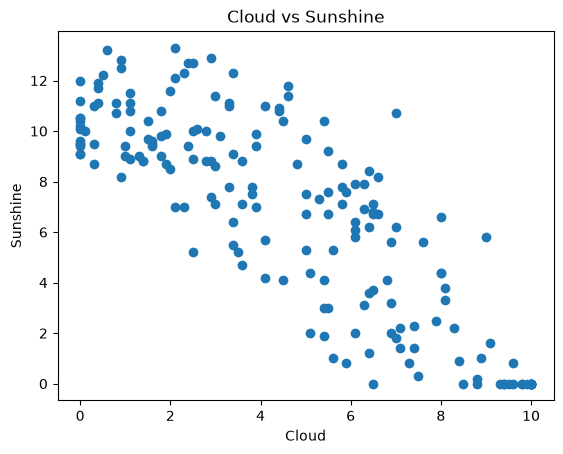

In [11]:
#시각화 코드(1)
plt.scatter(weather['cloud'], weather['sunshine'])

plt.xlabel('Cloud')
plt.ylabel('Sunshine')
plt.title('Cloud vs Sunshine')

plt.show()

STEP 2-2. 특성변수 후보와 목표변수의 관계 시각화하기(2)


In [10]:
#시각화 코드(2)

STEP3. 입력 데이터 X와 정답 y 정하기

In [10]:
X=weather[['temp','wind','humi','cloud']]
y=weather['sunshine']

print(X.head())
print(y.head())

            temp  wind  humi  cloud
date                               
2023-01-01  -0.2   2.7  55.0    1.3
2023-01-02  -4.5   2.5  46.0    0.0
2023-01-03  -5.0   1.8  49.0    0.0
2023-01-04  -1.8   1.9  51.0    1.9
2023-01-05  -1.6   1.6  58.1    3.6
date
2023-01-01    9.0
2023-01-02    9.1
2023-01-03    9.1
2023-01-04    8.7
2023-01-05    4.7
Name: sunshine, dtype: float64


STEP4. 훈련데이터와 테스트테이터로 분리하기

In [9]:
%pip install scikit-learn


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [12]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2, random_state=42
)
print('훈련 데이터:',X_train.shape)
print('테스트 데이터:',X_test.shape)

훈련 데이터: (144, 4)
테스트 데이터: (37, 4)


STEP5. 모델1: 선형회귀 모델 학습하기

In [13]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(X_train,y_train);

STEP6. 모델1: 테스트 데이터 예측하기

In [14]:
pred = model.predict(X_test)
result = pd.DataFrame({
    'original_index':y_test.index,
    'actual':y_test.values,
    'predicted':pred
})

STEP7. 모델1: 성능 평가하기

In [16]:
from sklearn.metrics import mean_absolute_error, r2_score
mae = mean_absolute_error(y_test,pred)
r2 = r2_score(y_test,pred)
print('MAE: ', mae)
print('R2: ', r2)

MAE:  1.4872732719755142
R2:  0.7737787722337529


STEP8. 모델2: 랜덤포레스트 학습, 예측, 성능평가 (STEP5~7 모델명만 바꿔서 학습)

In [17]:
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test,rf_pred)
rf_r2 = r2_score(y_test,rf_pred)

print("랜덤포레스트 MAE: ",rf_mae)
print("랜덤포레스트 R2: ",rf_r2)


랜덤포레스트 MAE:  1.4107837837837822
랜덤포레스트 R2:  0.7899235229883741


STEP9. 모델1과 모델2: 성능비교

In [18]:
print('선형회귀 MAE: ', mae)
print('선형회귀 R2: ', r2)
print("랜덤포레스트 MAE: ",rf_mae)
print("랜덤포레스트 R2: ",rf_r2)

선형회귀 MAE:  1.4872732719755142
선형회귀 R2:  0.7737787722337529
랜덤포레스트 MAE:  1.4107837837837822
랜덤포레스트 R2:  0.7899235229883741


STEP10. 성능 평가 결과로 모델 선정, 실제값과 예측값 시각화하기

<function matplotlib.pyplot.show(close=None, block=None)>

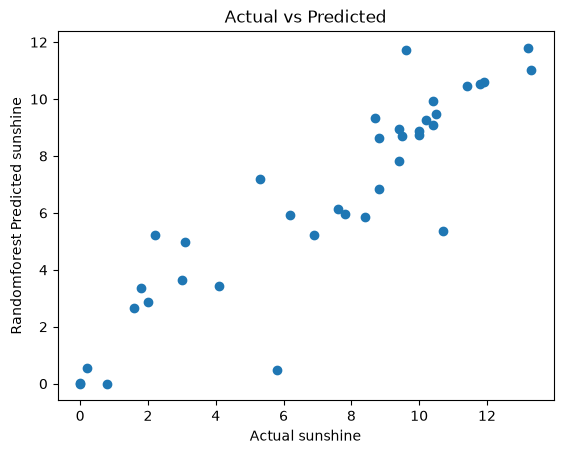

In [18]:
plt .scatter(y_test,rf_pred)
plt.xlabel('Actual sunshine')
plt.ylabel('Randomforest Predicted sunshine')
plt.title('Actual vs Predicted')
plt.show

STEP 11. 새로운 날씨 데이터 예측하기
 - X값 중 하나 이상을 바꾸어 새로운 날씨의 일조 시간 예측

In [20]:
new_weather = pd.DataFrame(
    {'temp':[20.0],
     'wind':[2.5],
     'humi':[60.0],
     'cloud':[4.0]
    })
new_pred = model.predict(new_weather)
print('예측 일조시간:',new_pred)

예측 일조시간: [8.46728864]


<회귀 모델 성능지표 해석>

MAE: 작을수록 좋음 (실제값과 예측값이 평균적으로 얼마나 차이 나는지?)

R²: 1에 가까울수록 좋음 (모델이 실제 데이터의 변화를 얼마나 잘 설명하는지?)